In [1]:
from backtest_external import *

# 回测基础数据路径
basic_data_path = '../data'

# 实例化
factorbacktest = FactorBacktest(basic_data_path = basic_data_path)

ModuleNotFoundError: No module named 'loguru'

### 示例因子

In [8]:
factor_demo = pd.read_parquet('/data/factor_demo.parquet')
factor_demo

code,000001.SZ,000002.SZ,000004.SZ,000005.SZ,000006.SZ,000007.SZ,000008.SZ,000009.SZ,000010.SZ,000011.SZ,...,688786.SH,688787.SH,688788.SH,688789.SH,688793.SH,688798.SH,688799.SH,688800.SH,688819.SH,688981.SH
date,,,,,,,,,,,,,,,,,,,,,
2023-01-03,0.191611,0.026424,0.041254,-0.057257,0.127506,0.090400,-0.052025,0.054228,0.018092,0.092087,...,-0.069407,0.020333,-0.004753,0.090233,0.006753,0.219137,-0.013393,0.079819,0.032636,0.018246
2023-01-04,0.103757,0.176937,0.074066,0.109451,0.161465,0.031626,0.042311,0.026917,0.057349,0.109264,...,-0.164233,0.094888,-0.093567,0.023594,0.048680,0.162511,-0.016457,-0.037116,-0.040156,0.115475
2023-01-05,-0.015840,0.074614,-0.044452,-0.022388,0.048841,0.039680,-0.104384,-0.008095,0.086566,0.192606,...,0.051827,-0.048457,-0.002566,0.065812,0.182632,0.193660,0.001100,0.125877,-0.046407,0.059196
2023-01-06,-0.042180,0.005443,-0.063144,0.033832,0.194214,-0.009349,-0.014116,-0.040487,0.287226,0.141054,...,-0.094366,-0.062048,-0.109551,-0.084261,0.187045,0.134015,-0.035851,0.169101,-0.082081,0.054083
2023-01-09,0.088583,0.033448,0.066336,0.153607,0.191493,0.095778,-0.014335,-0.095894,0.157576,0.146787,...,-0.154906,0.089601,-0.147379,-0.018870,0.204755,0.091668,0.021007,0.061708,-0.078424,-0.115136
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-06-05,-0.147995,0.046237,0.074661,-0.003376,-0.037569,0.042869,-0.000279,-0.081564,0.396610,-0.148038,...,0.003040,-0.050652,0.031413,-0.099362,0.000129,-0.068809,0.021630,0.015274,-0.155731,0.078997
2024-06-06,-0.114100,0.035959,0.022276,-0.002778,-0.056606,0.122834,0.133943,-0.045896,0.448869,-0.042954,...,-0.016408,-0.076831,-0.014239,-0.108144,0.076547,-0.062215,-0.062192,-0.021832,-0.060569,0.052171
2024-06-07,-0.045267,-0.086244,0.021488,-0.000514,-0.030466,0.010758,-0.085116,-0.094309,0.282036,-0.283840,...,-0.013400,0.001149,0.139441,-0.048733,0.156135,-0.066762,0.106601,0.056332,-0.219298,-0.085019


### 全市场回测

/home/yzh/Research/Alpha/demo/Backtest/code/backtest_external.py:198: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  industry=self.industry.ffill().bfill().loc[starttime:endtime, stock_group]
/home/yzh/Research/Alpha/demo/Backtest/code/backtest_external.py:552: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.3176735379994173' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  return_annual.loc[i]=(netvalue_df.iloc[-1,i]-1)/(len(netvalue_df)-1 -kk)*240
/home/yzh/Research/Alpha/demo/Backtest/code/backtest_external.py:553: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.079

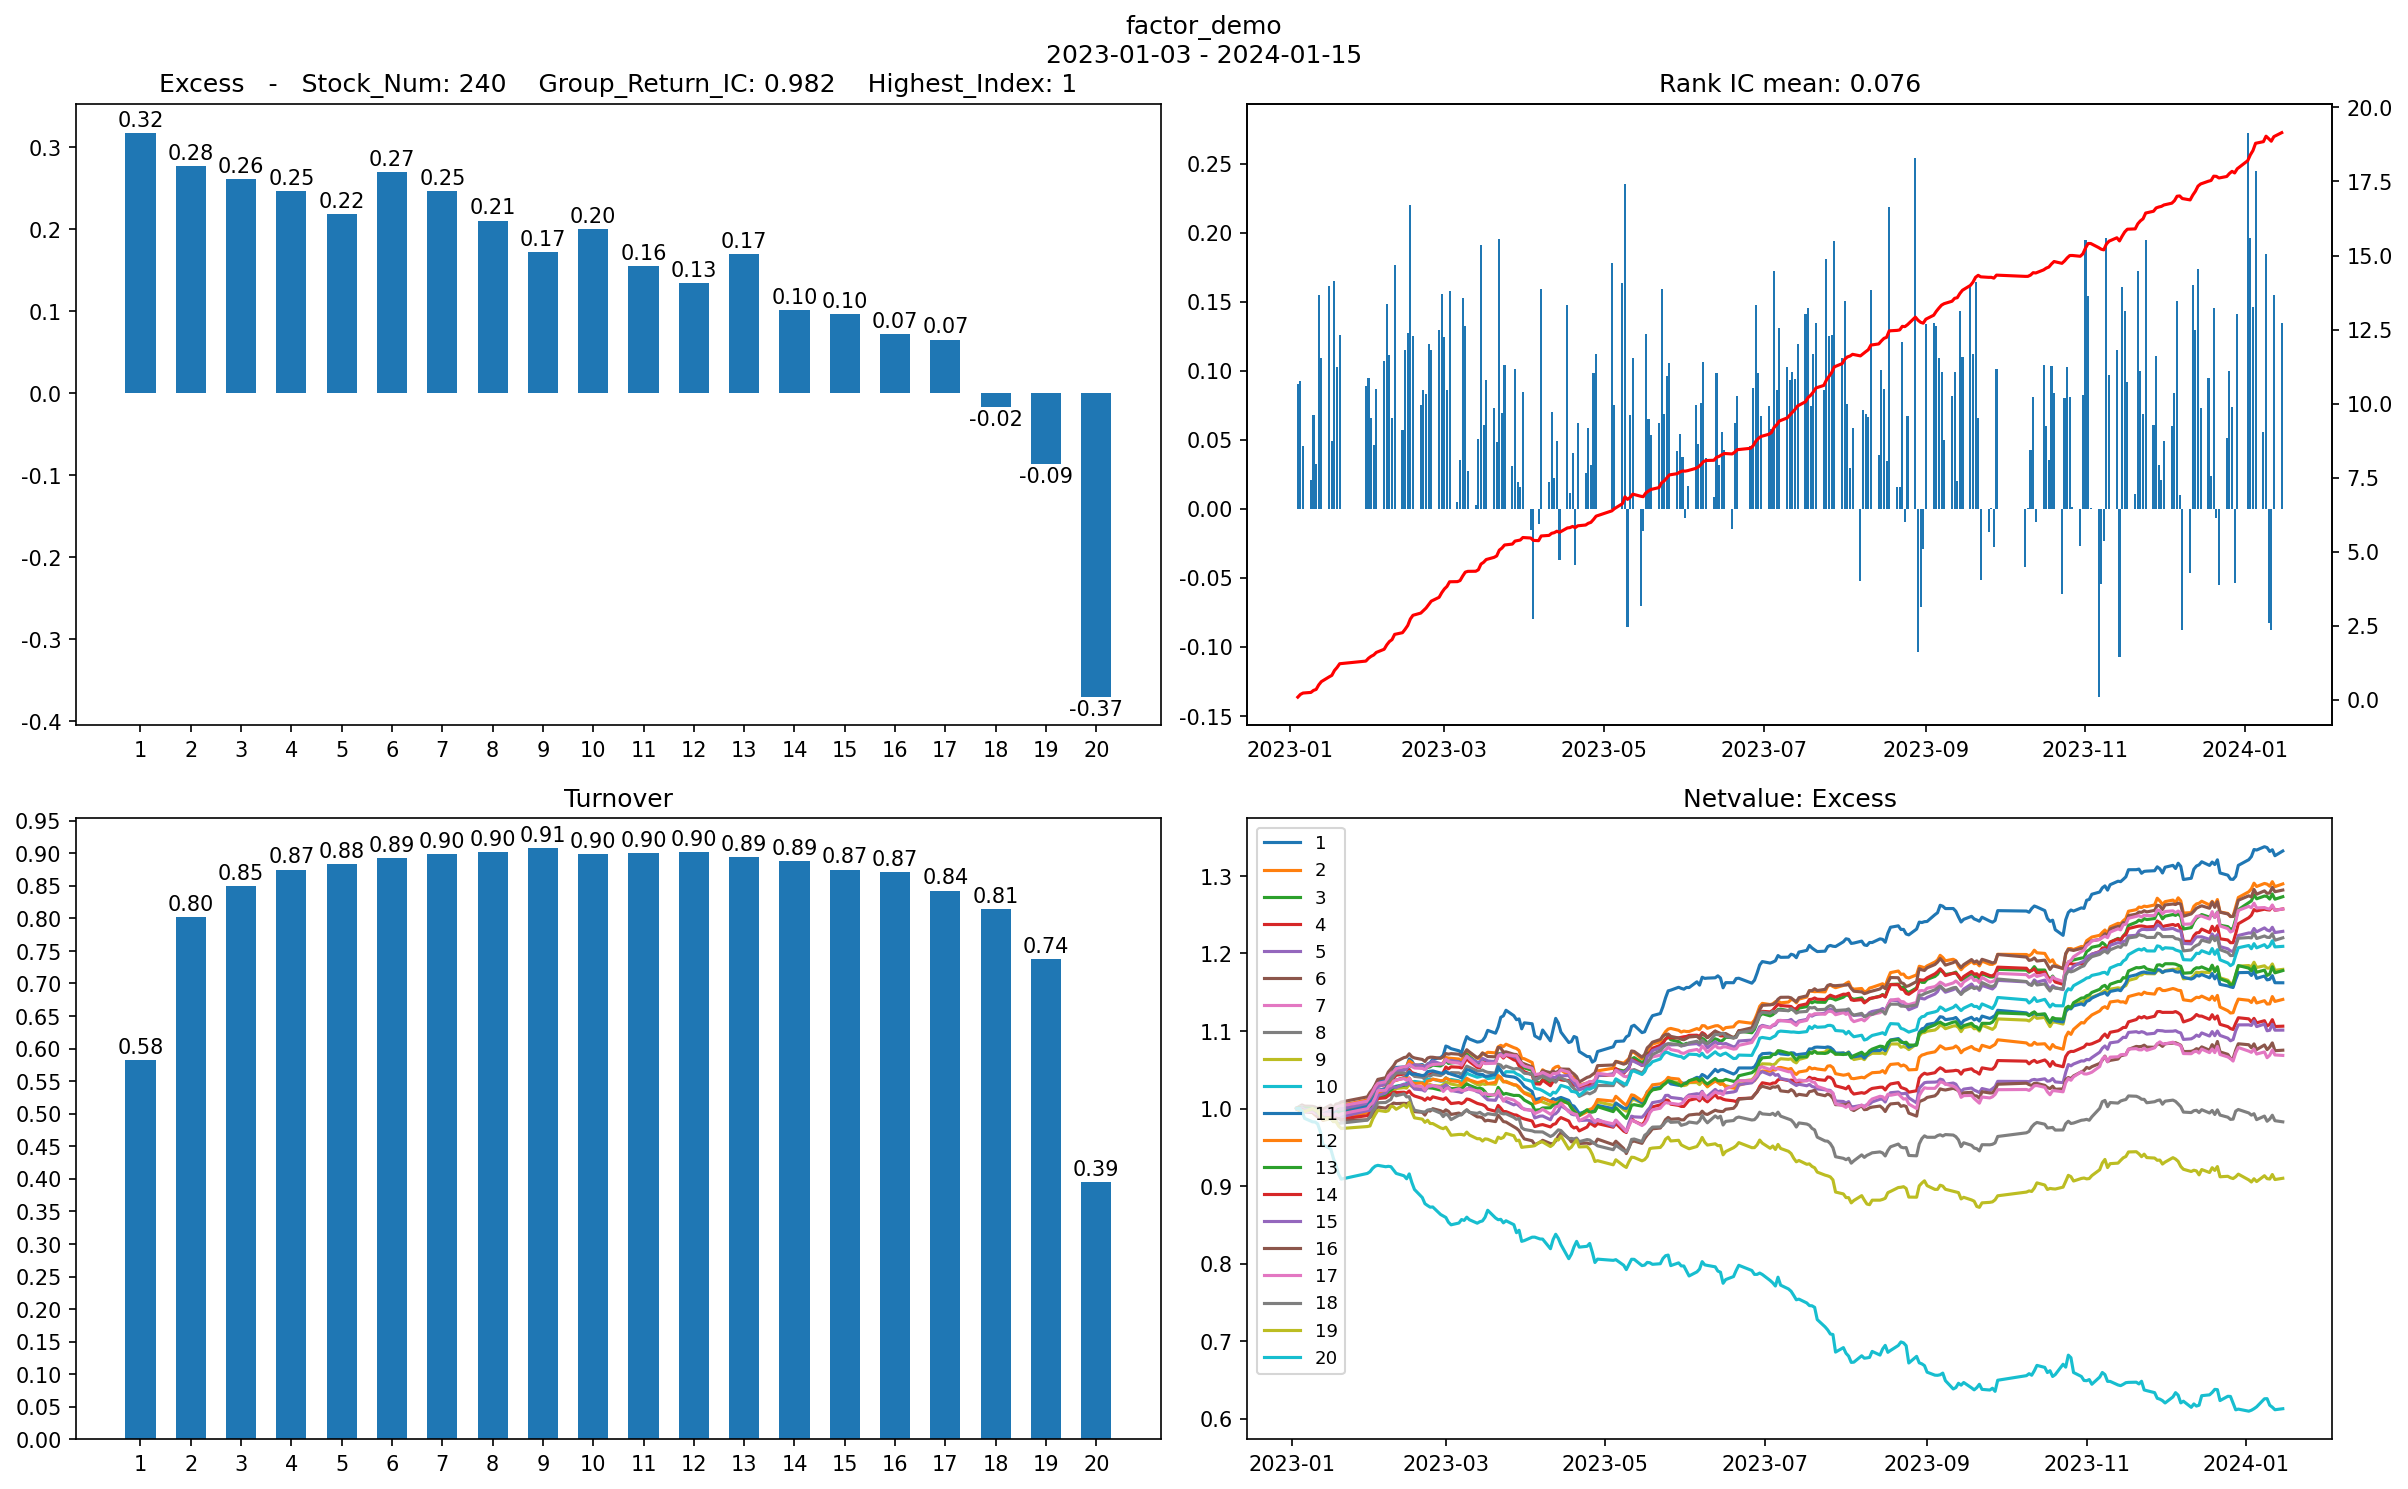

dict_keys(['return', 'group_return_ic', 'highest_index', 'rank_ic', 'rank_ic_cum', 'rank_ic_mean', 'turnover', 'turnover_df', 'netvalue', 'sharpe', 'cap_quantile', 'small_cap_rate', 'large_cap_rate', 'industry_rate'])

In [10]:
market_params = dict(
    factor = factor_demo, # 因子值
    start_date = factor_demo.index[0],  # 回测开始时间
    end_date = '2024-01-15',  # 回测结束时间
    nzp=True, # 因子是否中性化

    save_dir = '../backtest_result', # 回测结果保存位置
    save_name = 'factor_demo', # 回测图保存名
    plot_show = True,  # 是否显示回测结果
)

bt_market = factorbacktest.backtest(**market_params)
bt_market.keys()

### 指数内回测

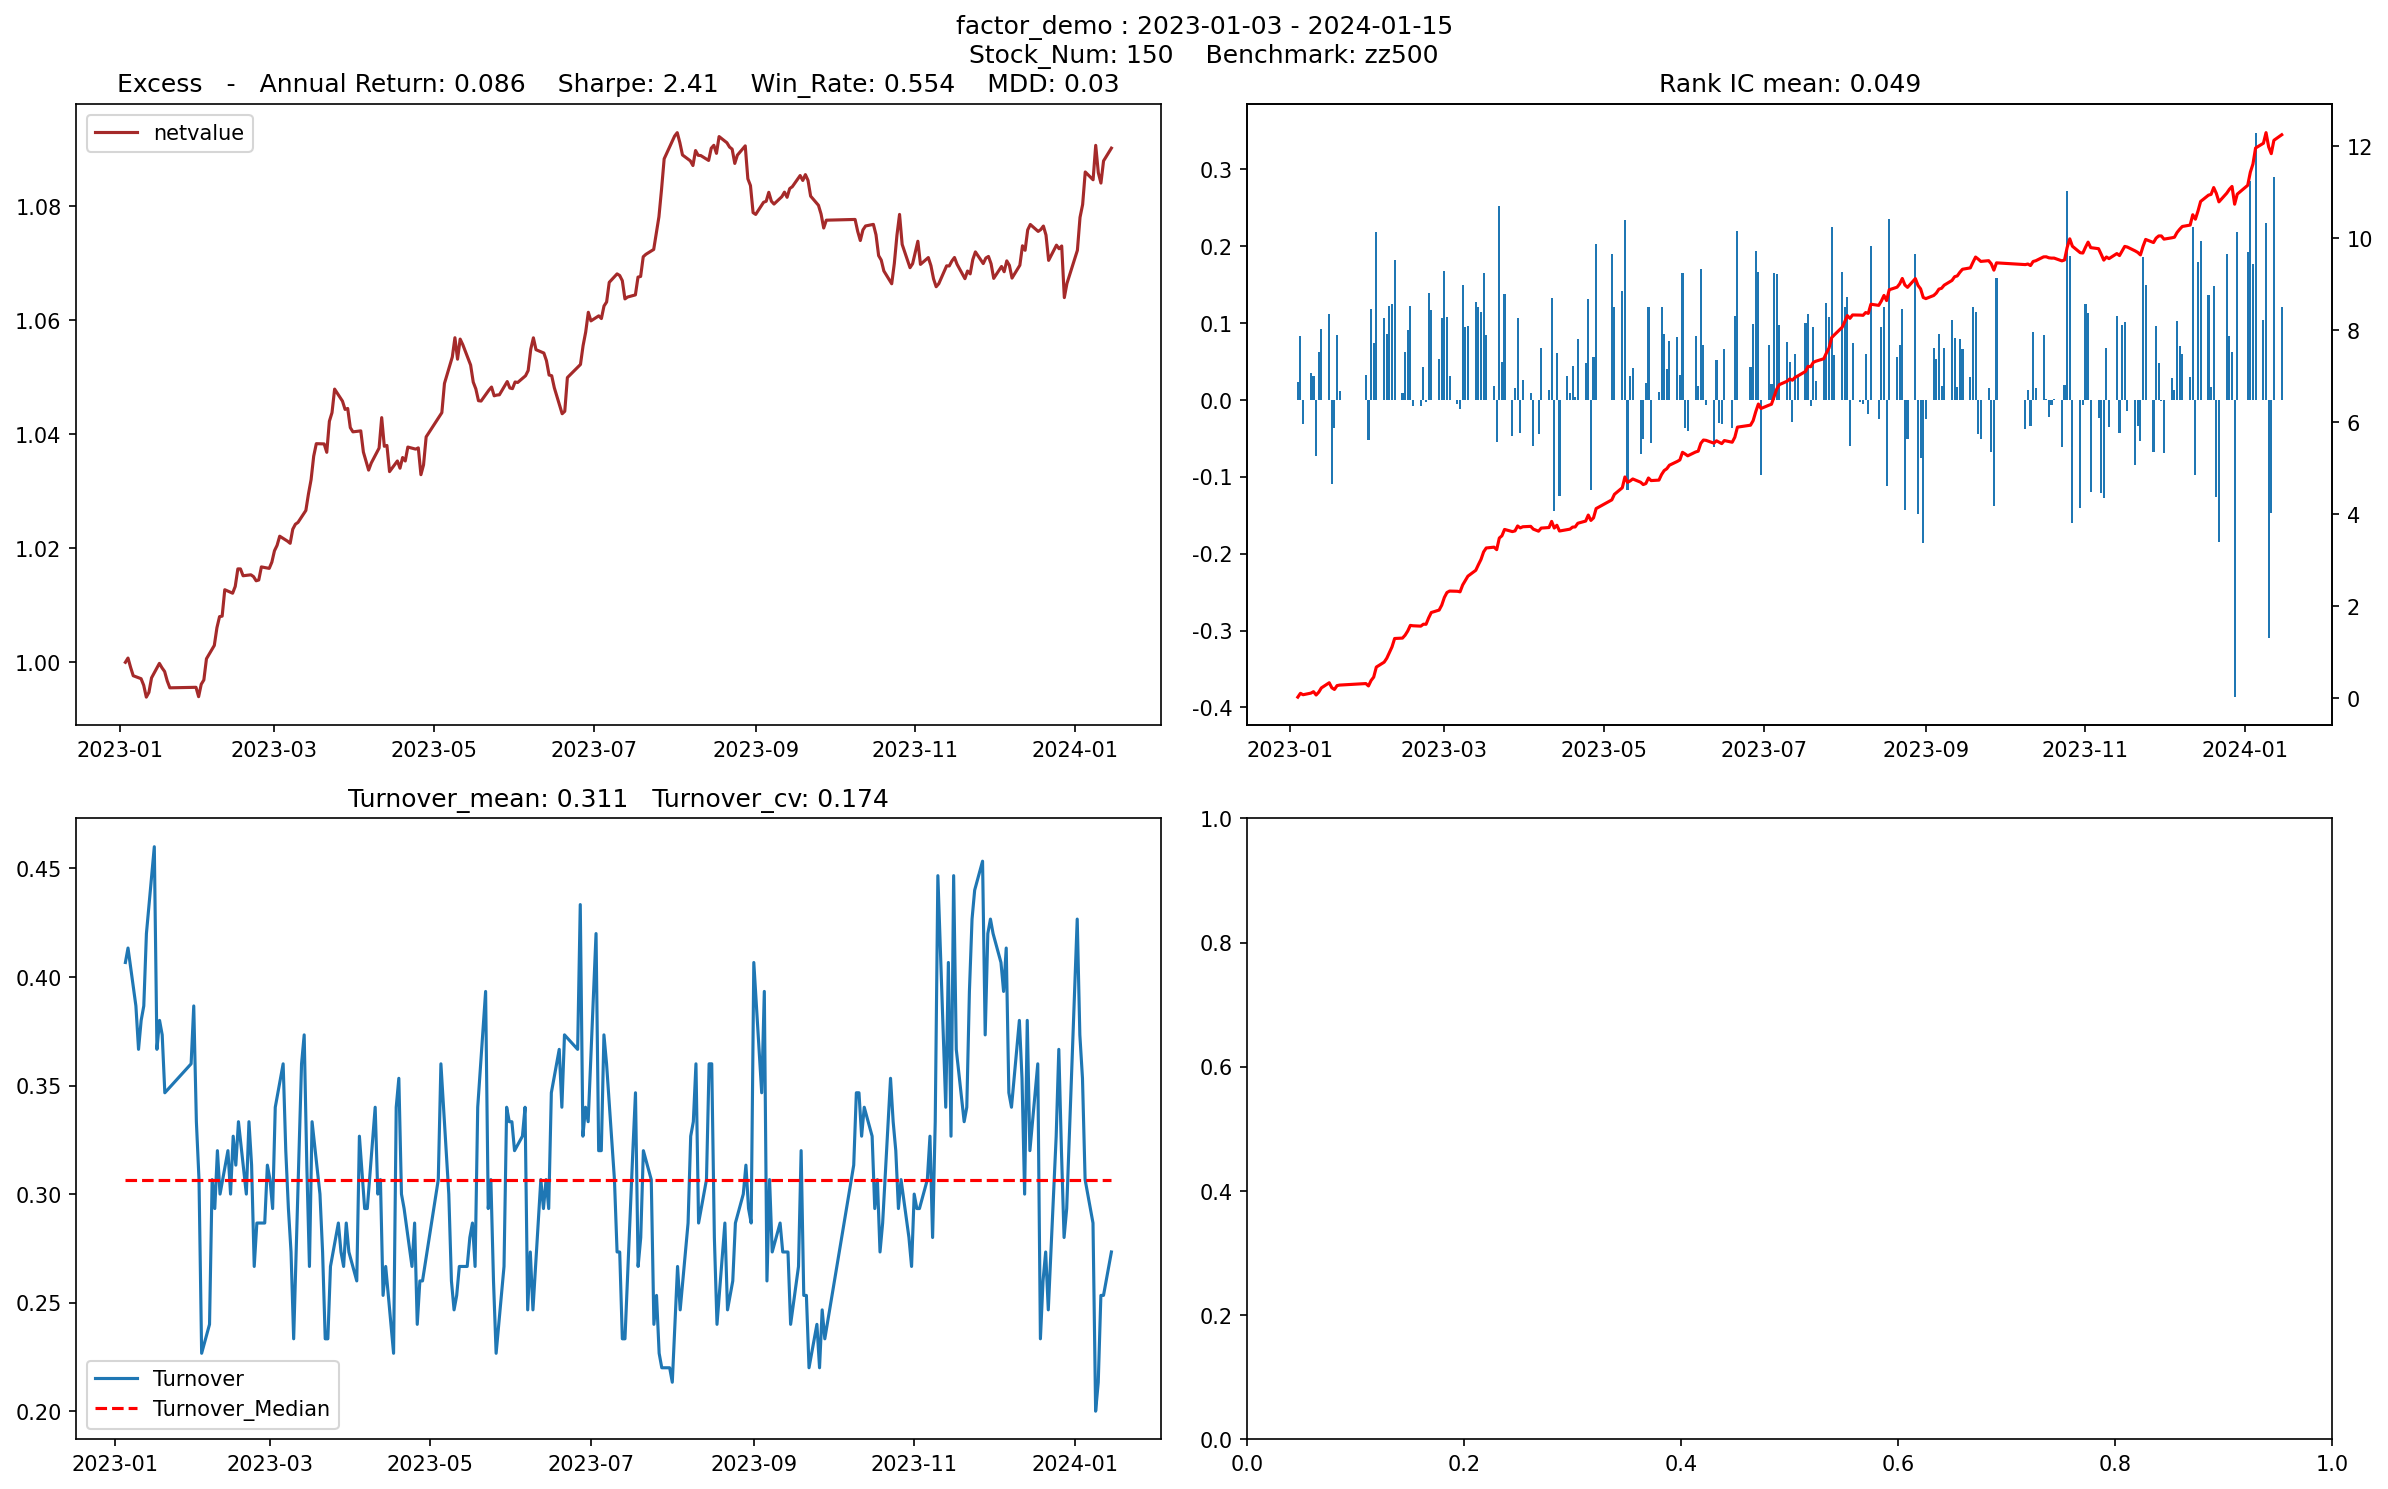

dict_keys(['return', 'sharpe', 'win_rate', 'mdd', 'netvalue', 'rank_ic', 'rank_ic_cum', 'rank_ic_mean', 'turnover', 'turnover_mean', 'turnover_median', 'turnover_cv'])

In [4]:
index_params = dict(
    factor = factor_demo,
    start_date = factor_demo.index[0],  
    end_date = '2024-01-15',  
    nzp=True, 
    
    save_dir = '../backtest_result',
    save_name = 'factor_demo',
    plot_show = True, 
)

bt_index = factorbacktest.backtest_index(**index_params)
bt_index.keys()